# Spiral undersampling + reco
In this notebook, you can create some masks in spiral shape to undersample the kspace to different level to finally test some reconstruction methods

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# load defined functions from utils.py
from utils import *
from uils_msk import *

## Loading files

In [2]:
#kspace
kspace_8st_slice = np.load("data/kspace_8st_slice.npy")
print(kspace_8st_slice.shape)

# Sensitivity maps
sensitivity_maps_8st_slice = np.load("data/sensitivity_maps_8st_slice.npy")
print(sensitivity_maps_8st_slice.shape)

(20, 320, 320)
(20, 320, 320)


# tutos from Claude

## Creating spiral mask Archimedean

In [3]:
# For your multi-coil k-space data with shape (num_coils, ny, nx)
num_coils = kspace_8st_slice.shape[0]
spiral_mask_archi = create_spiral_mask((kspace_8st_slice.shape[1], kspace_8st_slice.shape[2]), 
                                  num_spirals=8, 
                                  undersampling_factor=4)

# Apply same mask to all coils
kspace_undersampled = kspace_8st_slice.copy()
for coil in range(num_coils):
    kspace_undersampled[coil][~spiral_mask_archi] = 0

# Reconstruct image
img_undersampled = inverse_fft2_shift_1slice(kspace_undersampled)

# Check actual undersampling achieved
actual_sampling = np.sum(spiral_mask_archi) / (spiral_mask_archi.shape[0] * spiral_mask_archi.shape[1])
print(f"Actual sampling percentage: {actual_sampling*100:.1f}%")
print(f"Acceleration factor: {1/actual_sampling:.2f}x")

Actual sampling percentage: 83.5%
Acceleration factor: 1.20x


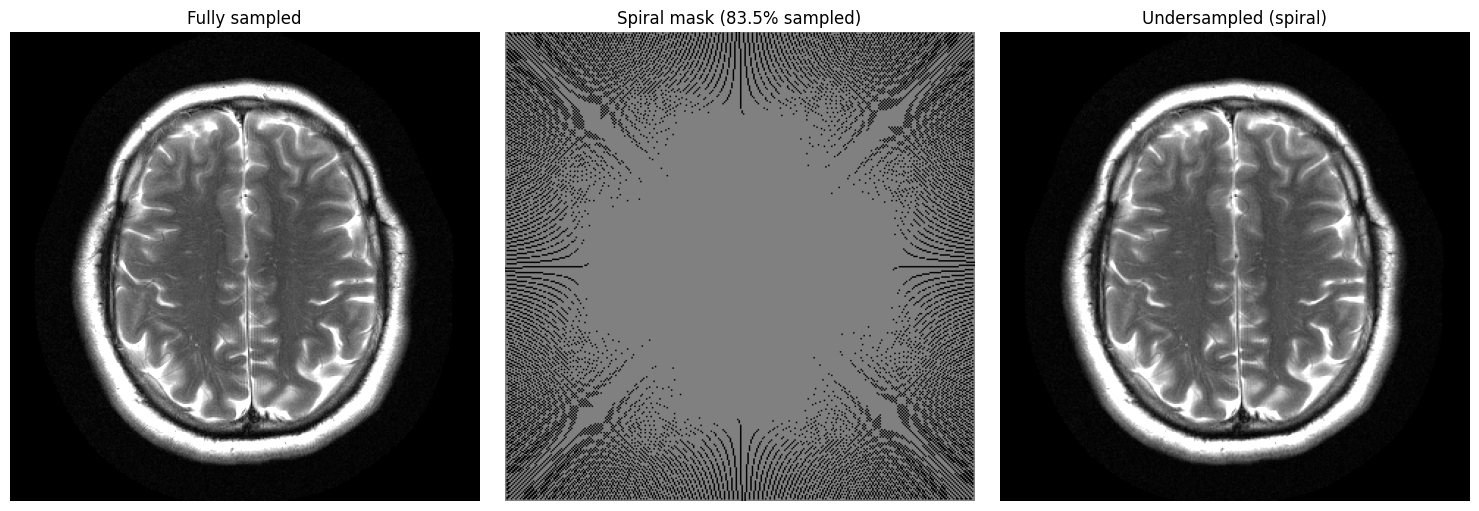

In [11]:
# Compare fully sampled vs undersampled reconstruction
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Fully sampled
# SENSE with normalization multi coil combination
img_full = (sensitivity_maps_8st_slice.conj() * inverse_fft2_shift_1slice(kspace_8st_slice)).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0) + np.finfo(float).eps)
axes[0].imshow(np.abs(img_full), cmap='gray', vmax=4e-4)
axes[0].set_title('Fully sampled')

# Spiral mask
axes[1].imshow(spiral_mask_archi, cmap='gray', vmax=2)
axes[1].set_title(f'Spiral mask ({actual_sampling*100:.1f}% sampled)')

# Undersampled reconstruction
img_under = (sensitivity_maps_8st_slice.conj() * inverse_fft2_shift_1slice(kspace_undersampled)).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0) + np.finfo(float).eps)
axes[2].imshow(np.abs(img_under), cmap='gray',vmax=4e-4)
axes[2].set_title('Undersampled (spiral)')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Creating golden angle spiral

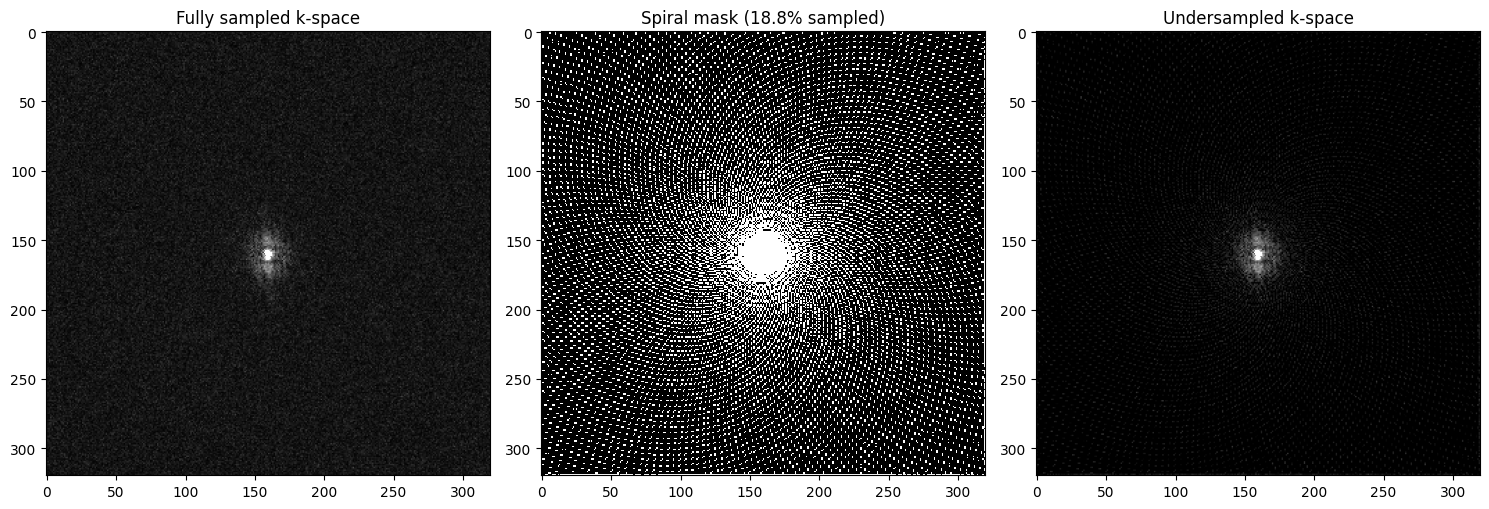

In [12]:
# Create mask with 16 spirals
spiral_mask_golden = create_golden_angle_spiral((kspace_8st_slice.shape[1], kspace_8st_slice.shape[2]), num_spirals=16, undersampling_factor=4)

# Visualize with better settings
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Fully sampled
axes[0].imshow(np.log(np.abs(kspace_8st_slice[0]) + 1), cmap='gray', vmax= 1e-4)
axes[0].set_title('Fully sampled k-space')

# Spiral mask - zoom to center to see pattern better
axes[1].imshow(spiral_mask_golden, cmap='gray', interpolation='nearest')
axes[1].set_title(f'Spiral mask ({np.sum(spiral_mask_golden)/(320*320)*100:.1f}% sampled)')
"""# Optionally zoom to center
axes[1].set_xlim([100, 220])
axes[1].set_ylim([220, 100])  # inverted for image coordinates"""

# Undersampled
kspace_under = kspace_8st_slice.copy()
kspace_under[:, ~spiral_mask_golden] = 0
axes[2].imshow(np.log(np.abs(kspace_under[0]) + 1), cmap='gray', vmax= 1e-4)
axes[2].set_title('Undersampled k-space')

plt.tight_layout()
plt.show()

Actual sampling percentage: 18.8%
Acceleration factor: 5.31x
Number of spirales : 16
RMSE golden spiral R={1/actual_sampling:.2f}x ref FS SENSE normalised:  14.915232255060838  %


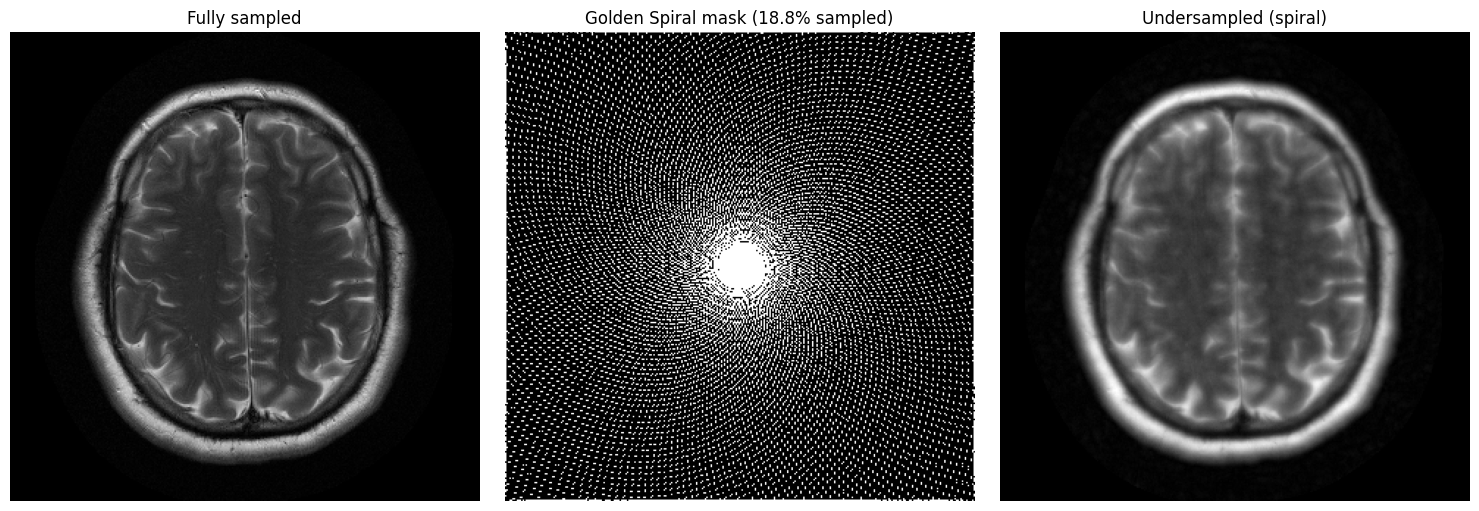

In [13]:
# Compare fully sampled vs undersampled reconstruction
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Apply same mask to all coils
kspace_undersampled = kspace_8st_slice.copy()
for coil in range(num_coils):
    kspace_undersampled[coil][~spiral_mask_golden] = 0

# Reconstruct image
img_undersampled = inverse_fft2_shift_1slice(kspace_undersampled)

# Check actual undersampling achieved
actual_sampling = np.sum(spiral_mask_golden) / (spiral_mask_golden.shape[0] * spiral_mask_golden.shape[1])
print(f"Actual sampling percentage: {actual_sampling*100:.1f}%")
print(f"Acceleration factor: {1/actual_sampling:.2f}x")
print(f"Number of spirales : 16")

# Fully sampled image SENSE with normalization multi coil combination
img_full = (sensitivity_maps_8st_slice.conj() * inverse_fft2_shift_1slice(kspace_8st_slice)).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0) + np.finfo(float).eps)
axes[0].imshow(np.abs(img_full), cmap='gray')
axes[0].set_title('Fully sampled')

# Spiral mask
axes[1].imshow(spiral_mask_golden, cmap='gray')
axes[1].set_title(f'Golden Spiral mask ({actual_sampling*100:.1f}% sampled)')

# Undersampled reconstruction
img_under = (sensitivity_maps_8st_slice.conj() * inverse_fft2_shift_1slice(kspace_undersampled)).sum(0) / ((abs(sensitivity_maps_8st_slice)**2).sum(0) + np.finfo(float).eps)
axes[2].imshow(np.abs(img_under), cmap='gray')
axes[2].set_title('Undersampled (spiral)')

# calculate the Root Mean Squared Error
rmse_golden_spiral = nrmse(img_under, img_full)
print('RMSE golden spiral R={1/actual_sampling:.2f}x ref FS SENSE normalised: ', rmse_golden_spiral, ' %')


for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

In [14]:
# Fully sampled image SENSE with normalization multi coil combination
axes[0].imshow(np.abs(img_full), cmap='gray')
axes[0].set_title('Fully sampled')
plt.show()

# Spirals created from scratch
test avec turtle, pas de display...

## Fibonacci spiral